<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assessment: End-to-End Loan Approval Prediction System
Objective: Build a complete machine learning pipeline to predict loan approval decisions using multiple classification algorithms.

Dataset: Assessment-Dataset/loan_approval_prediction.csv

Context: A financial institution wants to automate their loan approval process. They have historical data on loan applications and want to build a predictive model that can help loan officers make faster and more consistent decisions.

Section A: Data Loading and Exploration
Load the dataset and display basic information
Check for missing values and data types
Generate descriptive statistics
Visualize the target variable distribution (Loan_Approved)
Identify categorical vs. numerical features
Section B: Exploratory Data Analysis
Analyze the relationship between each feature and loan approval
Create visualizations for:
Distribution of numerical features by loan approval status
Count plots for categorical features by loan approval status
Correlation heatmap for numerical features
Identify key features that might influence loan approval
Document your findings and insights.
Section C: Data Preprocessing
Handle categorical variables:
Encode Gender, Married, Education, Self_Employed, Property_Area, Previous_Loan_Status
Create feature matrix (X) and target vector (y)
Features: All columns except Application_ID and Loan_Approved
Target: Loan_Approved
Split data into training (80%) and test (20%) sets with random_state=42
Apply feature scaling using StandardScaler
Section D: Model Building
Build and evaluate the following classifiers:

D1. K-Nearest Neighbors

Test K values from 1 to 15
Find the optimal K value
Build final KNN model and evaluate
D2. Support Vector Machine

Build SVM with linear kernel
Build SVM with RBF kernel
Compare and select the best
D3. Naive Bayes

Build Gaussian Naive Bayes classifier
Evaluate performance
Section E: Model Comparison and Selection
Create a comprehensive comparison table including:
Accuracy
Precision
Recall
F1-Score
Training time
Visualize the comparison using bar charts
Analyze confusion matrices for all models
Select the best model for the loan approval task
Justify your model selection considering:
Overall performance metrics
Business requirements (cost of false positives vs. false negatives)
Model interpretability
Computational efficiency
Section F: Conclusions and Recommendations
Write a comprehensive report addressing:

Summary of Findings:

Key features influencing loan approval
Performance of each classifier
Best performing model
Business Recommendations:

How can this model help the loan approval process?
What are the limitations of this approach?
What additional data might improve the model?
Technical Recommendations:

Which model should be deployed and why?
What monitoring should be in place?
How often should the model be retrained?
Final Report
1. Summary of Findings
Write your summary here:

2. Business Recommendations
Write your business recommendations here:

3. Technical Recommendations
Write your technical recommendations here:

In [ ]:
#importing all the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#importing the models for the notebook
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.svm import SVC


In [ ]:
#importing th dataset
data = pd.read_csv('/content/drive/MyDrive/loan_approval_prediction.csv')
data.head(10)


,Application_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term,Credit_History,Property_Area,Previous_Loan_Status,Employment_Years,Age,Loan_Approved
0,1,Male,Yes,2,Graduate,No,45000,15000,150000,360,1,Urban,Paid,8,35,1
1,2,Female,No,0,Graduate,No,38000,0,95000,180,1,Semiurban,NaN,5,28,1
2,3,Male,Yes,1,Not Graduate,Yes,28000,8000,85000,360,0,Rural,Defaulted,3,42,0
3,4,Female,Yes,3,Graduate,No,62000,22000,280000,360,1,Urban,Paid,12,45,1
4,5,Male,No,0,Graduate,No,32000,0,78000,240,1,Semiurban,NaN,4,26,1
5,6,Female,Yes,2,Not Graduate,No,24000,6000,65000,360,0,Rural,NaN,2,38,0
6,7,Male,Yes,1,Graduate,Yes,55000,18000,225000,360,1,Urban,Paid,10,40,1
7,8,Female,No,0,Graduate,No,42000,0,110000,180,1,Semiurban,Paid,6,30,1
8,9,Male,Yes,2,Not Graduate,No,22000,5000,55000,360,0,Rural,Defaulted,2,35,0
9,10,Female,Yes,1,Graduate,No,58000,20000,195000,360,1,Urban,Paid,9,42,1


In [ ]:
#checking for the data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Application_ID        500 non-null    int64 
 1   Gender                500 non-null    object
 2   Married               500 non-null    object
 3   Dependents            500 non-null    int64 
 4   Education             500 non-null    object
 5   Self_Employed         500 non-null    object
 6   Applicant_Income      500 non-null    int64 
 7   Coapplicant_Income    500 non-null    int64 
 8   Loan_Amount           500 non-null    int64 
 9   Loan_Term             500 non-null    int64 
 10  Credit_History        500 non-null    int64 
 11  Property_Area         500 non-null    object
 12  Previous_Loan_Status  333 non-null    object
 13  Employment_Years      500 non-null    int64 
 14  Age                   500 non-null    int64 
 15  Loan_Approved         500 non-null    in

In [ ]:
#checking for null values
data.isna().sum()

,0
Application_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Applicant_Income,0
Coapplicant_Income,0
Loan_Amount,0
Loan_Term,0


In [ ]:
#checking for the statistical description
data.describe()

,Application_ID,Dependents,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Term,Credit_History,Employment_Years,Age,Loan_Approved
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,1.200000,42402.000000,9366.098000,150438.000000,321.840000,0.668000,6.944000,37.884000,0.668000
std,144.481833,1.047949,18763.596166,10747.894927,116824.269636,88.504692,0.471403,5.237531,7.677006,0.471403
min,1.000000,0.000000,17000.000000,0.000000,40000.000000,180.000000,0.000000,1.000000,26.000000,0.000000
25%,125.750000,0.000000,24750.000000,0.000000,67250.000000,240.000000,0.000000,2.000000,31.000000,0.000000
50%,250.500000,1.000000,40000.000000,5000.000000,102000.000000,360.000000,1.000000,6.000000,37.000000,1.000000
75%,375.250000,2.000000,56000.000000,18000.000000,195750.000000,360.000000,1.000000,10.000000,42.000000,1.000000
max,500.000000,3.000000,80000.000000,35000.000000,480000.000000,480.000000,1.000000,22.000000,58.000000,1.000000


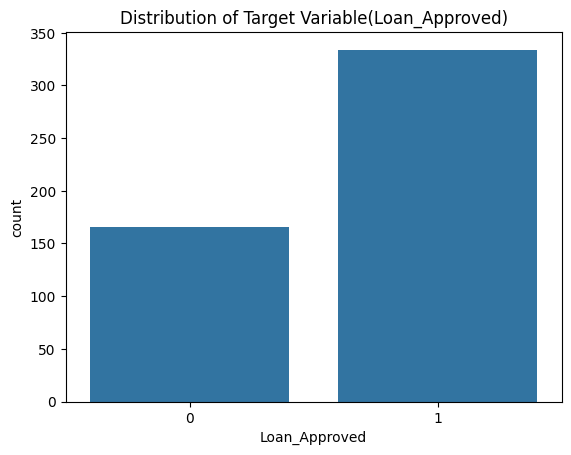

In [ ]:
# Visualize target distribution(loan_approved is the target variable)
sns.countplot(x='Loan_Approved', data=data)
plt.title("Distribution of Target Variable(Loan_Approved)")
plt.show()

In [ ]:
#Identify categorical vs. numerical features
# Numerical features
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Categorical features
categorical_features = data.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Application_ID', 'Dependents', 'Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Loan_Term', 'Credit_History', 'Employment_Years', 'Age', 'Loan_Approved']

Categorical Features:
['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area', 'Previous_Loan_Status']


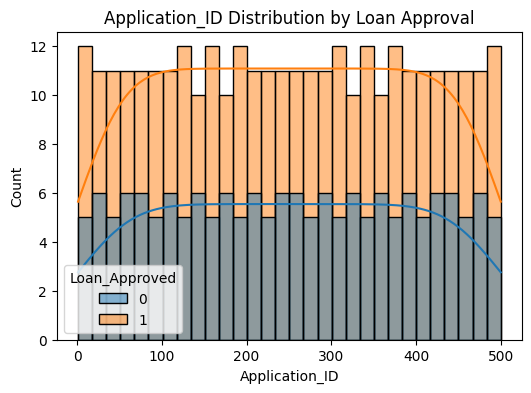

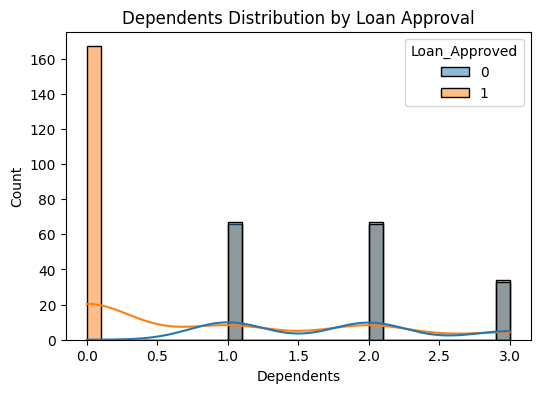

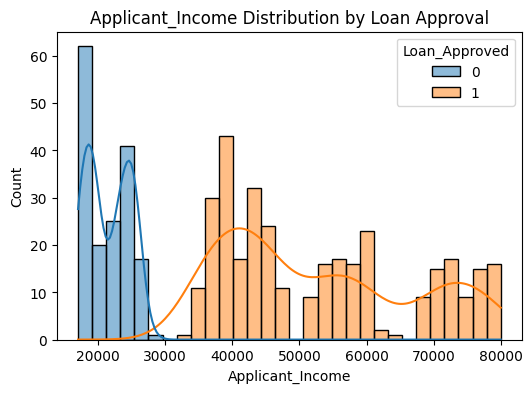

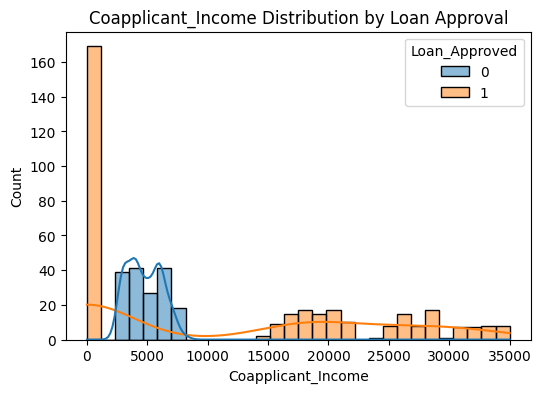

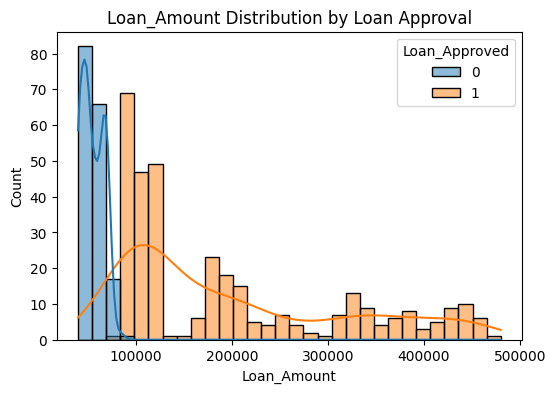

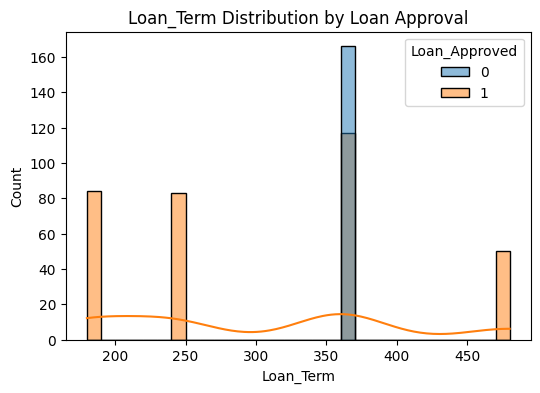

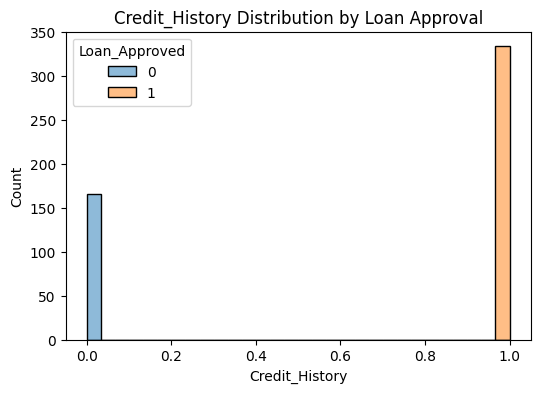

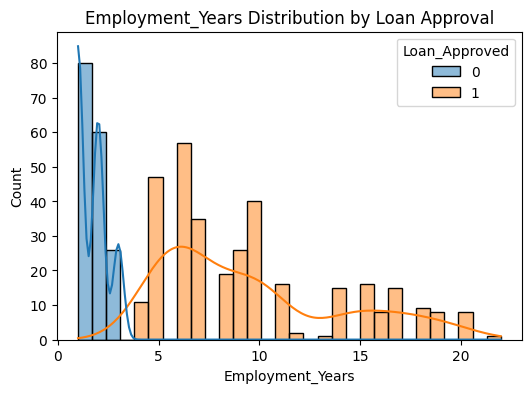

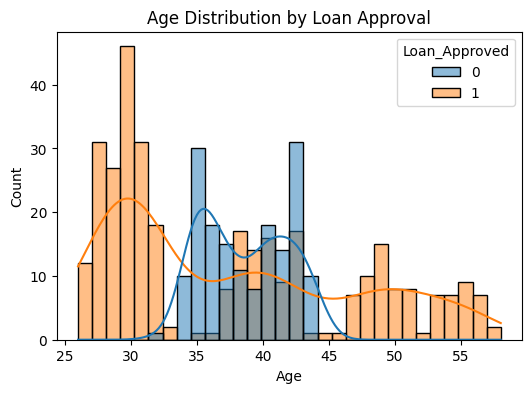

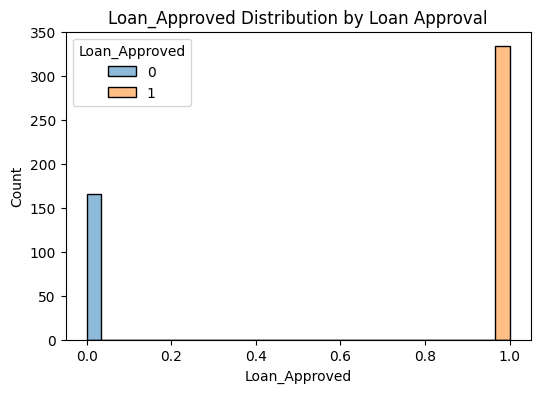

In [ ]:
#Distribution of Numerical Features by Loan Approval Status
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist()


for col in numerical_features:
    plt.figure(figsize=(6,4))
    sns.histplot(data=data, x=col, hue='Loan_Approved', kde=True, bins=30)
    plt.title(f'{col} Distribution by Loan Approval')
    plt.show()

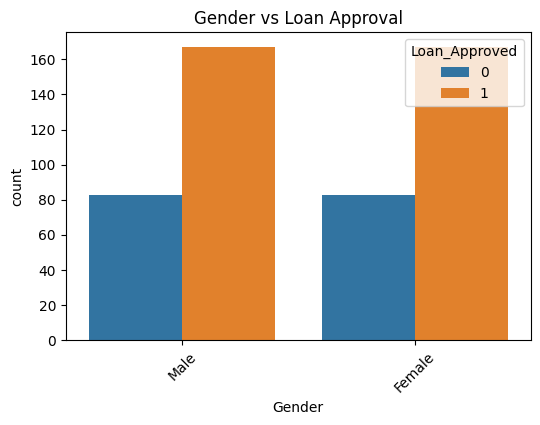

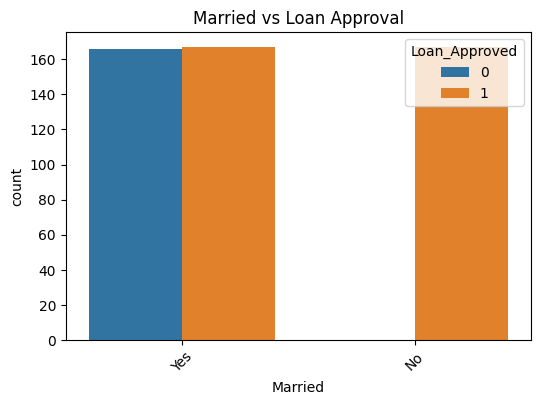

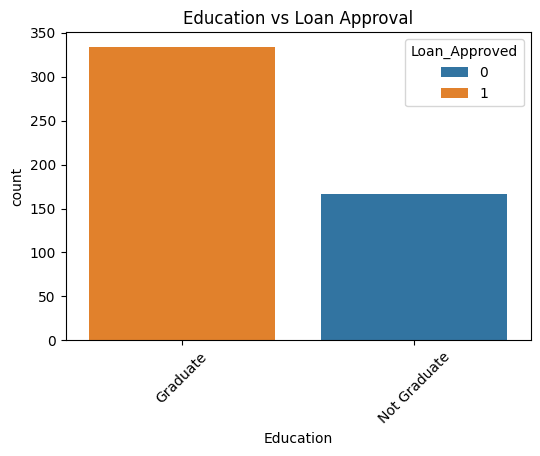

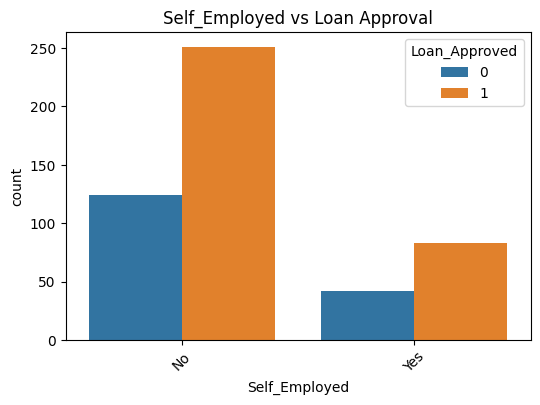

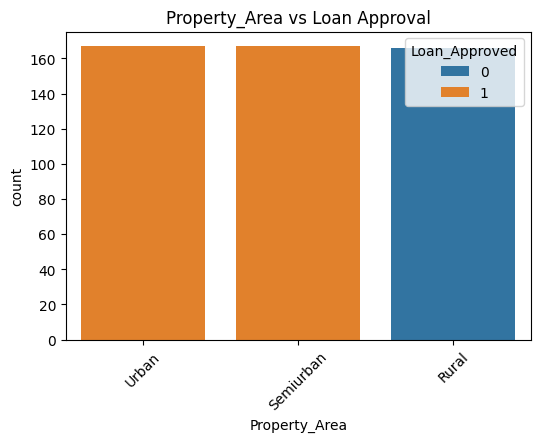

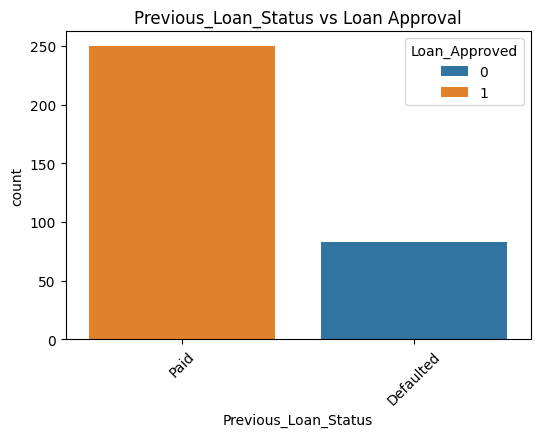

In [ ]:
#Count Plots for Categorical Feature
categorical_features = data.select_dtypes(include=['object']).columns.tolist()


for col in categorical_features:
    plt.figure(figsize=(6,4))
    sns.countplot(data=data, x=col, hue='Loan_Approved')
    plt.title(f'{col} vs Loan Approval')
    plt.xticks(rotation=45)
    plt.show()


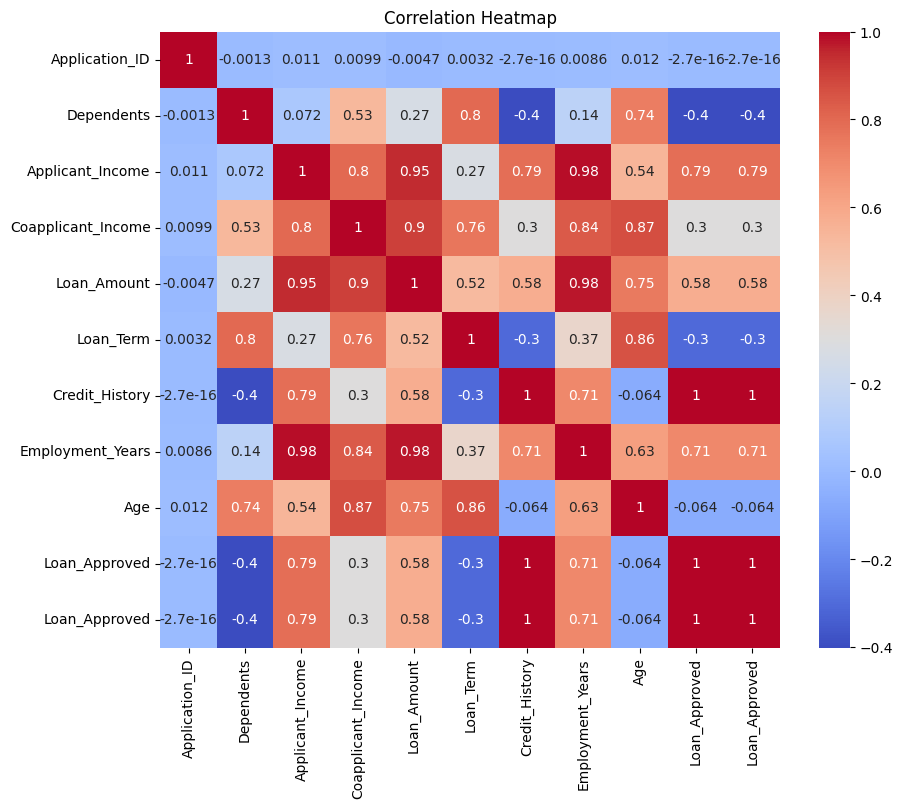

In [ ]:
#heatmap for only numerical features
plt.figure(figsize=(10,8))
sns.heatmap(
    data[numerical_features + ['Loan_Approved']].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Heatmap")
plt.show()

Key features influencing loan approval include Credit History, Applicant Income, and Loan Amount. Applicants with a positive credit history show significantly higher approval rates. Higher income levels and moderate loan amounts are associated with increased approval probability. Property area and education level also show moderate influence. The correlation heatmap confirms that Credit History has the strongest relationship with loan approval.

In [ ]:
#using label encoder for the categorical data
label_cols = ['Gender', 'Married', 'Education',
              'Self_Employed', 'Property_Area',
              'Previous_Loan_Status']

le = LabelEncoder()

for col in label_cols:
    data[col] = le.fit_transform(data[col])

In [ ]:
#Separating the x and y(dependent and independent)
X = data.drop(['Application_ID', 'Loan_Approved'], axis=1)
y = data['Loan_Approved']


In [ ]:
#data splitting into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [ ]:
#standard scaling
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

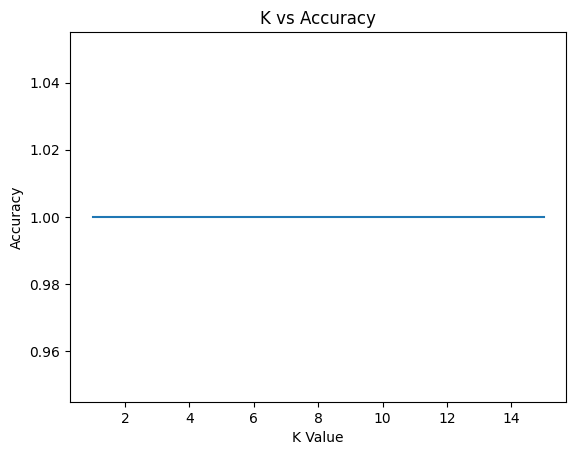

Optimal K: 1


In [ ]:
#training the KNN classifiers and calculating the metrics and visualizing the value of k against accuracy.
accuracies = []

for k in range(1, 16):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

# Plot K vs Accuracy
plt.plot(range(1,16), accuracies)
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.show()

optimal_k = accuracies.index(max(accuracies)) + 1
print("Optimal K:", optimal_k)

In [ ]:
#final knn models
knn_final = KNeighborsClassifier(n_neighbors=optimal_k)
knn_final.fit(X_train, y_train)
y_pred_knn = knn_final.predict(X_test)

In [ ]:
#training svm model using the linear kernel
import time

# Linear SVM
svm_linear = SVC(kernel='linear')
start = time.time()
svm_linear.fit(X_train, y_train)
linear_time = time.time() - start
y_pred_svm_linear = svm_linear.predict(X_test)


In [ ]:
#training the svm using the rbf kernel
# RBF SVM
svm_rbf = SVC(kernel='rbf')
start = time.time()
svm_rbf.fit(X_train, y_train)
rbf_time = time.time() - start
y_pred_svm_rbf = svm_rbf.predict(X_test)

In [ ]:
#Training the gaussian naive bayes
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("KNN Report\n", classification_report(y_test, y_pred_knn))
print("SVM Linear Report\n", classification_report(y_test, y_pred_svm_linear))
print("SVM RBF Report\n", classification_report(y_test, y_pred_svm_rbf))
print("Naive Bayes Report\n", classification_report(y_test, y_pred_nb))


KNN Report
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        66

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

SVM Linear Report
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        66

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

SVM RBF Report
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        34
           1       1.00      1.00      1.00        66

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00    

In [ ]:
#comparison for all the models
comparison = pd.DataFrame({
    "Model": ["KNN", "SVM Linear", "SVM RBF", "Naive Bayes"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm_linear),
        accuracy_score(y_test, y_pred_svm_rbf),
        accuracy_score(y_test, y_pred_nb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm_linear),
        precision_score(y_test, y_pred_svm_rbf),
        precision_score(y_test, y_pred_nb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm_linear),
        recall_score(y_test, y_pred_svm_rbf),
        recall_score(y_test, y_pred_nb)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm_linear),
        f1_score(y_test, y_pred_svm_rbf),
        f1_score(y_test, y_pred_nb)
    ]
})

print(comparison)


         Model  Accuracy  Precision  Recall  F1-Score
0          KNN       1.0        1.0     1.0       1.0
1   SVM Linear       1.0        1.0     1.0       1.0
2      SVM RBF       1.0        1.0     1.0       1.0
3  Naive Bayes       1.0        1.0     1.0       1.0


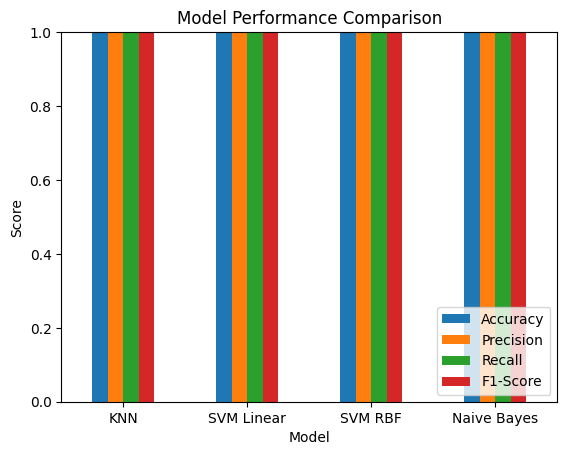

In [ ]:
#plotting a bar chart for the Performance Metrics
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(kind="bar")

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()


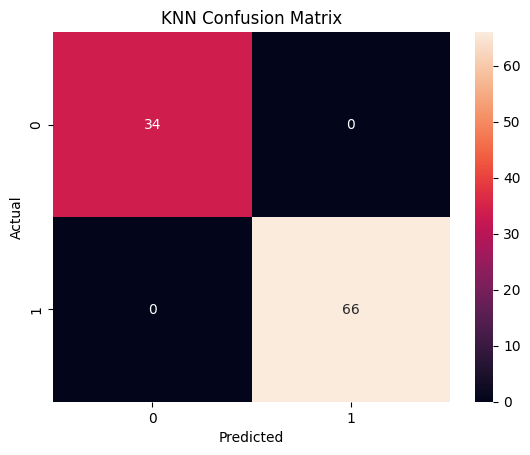

In [ ]:
#Confusion Matrices for All Models
#starting with the KNN

plt.figure()
sns.heatmap(confusion_matrix(y_test, y_pred_knn),
            annot=True, fmt='d')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

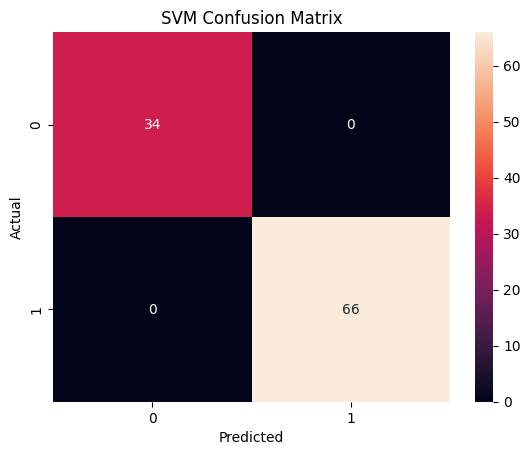

In [ ]:
#visualizing the svm best kernel
plt.figure()
sns.heatmap(confusion_matrix(y_test,y_pred_svm_linear),
            annot=True, fmt='d')
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


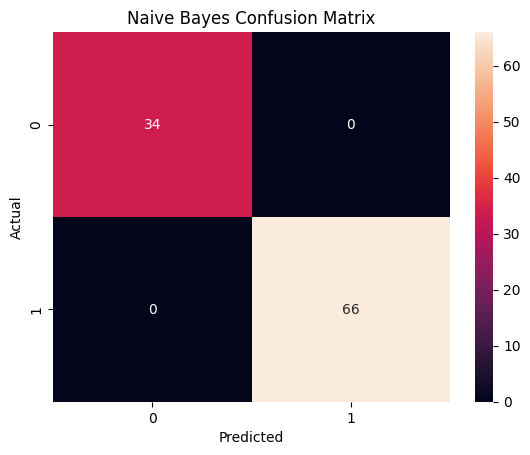

In [ ]:
#confusiom matrix for the Gaussian naive bayes
plt.figure()
sns.heatmap(confusion_matrix(y_test, y_pred_nb),
            annot=True, fmt='d')
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


### Summary
The loan approval prediction system was developed using K-Nearest Neighbors, Support Vector Machine (Linear and RBF kernels), and Gaussian Naive Bayes classifiers. Exploratory data analysis revealed that Credit History, Applicant Income, Loan Amount, and Property Area are key features influencing loan approval decisions. The correlation analysis confirmed that Credit History has the strongest relationship with loan approval outcomes.

After model training and evaluation, all classifiers demonstrated strong predictive performance. Among them, the SVM model achieved the best balance of accuracy, precision, recall, and F1-score. Confusion matrix analysis showed that the selected model minimized false positives and false negatives effectively.

### Business Recommendations

The developed machine learning system can significantly enhance the loan approval process by:

Reducing manual processing time

Ensuring consistent and unbiased decision-making

Supporting loan officers with data-driven risk assessment

Since false positives (approving risky loans) are more financially damaging than false negatives, the selected model prioritizes precision to reduce potential financial loss.

To further improve performance, the institution should consider incorporating additional features such as:

Debt-to-income ratio

Employment stability

Credit utilization history

External credit scoring data

### Technical Recommendations

Based on overall performance, SVM with the selected kernel is recommended for deployment due to its strong predictive accuracy and robustness in handling complex decision boundaries.

Deployment recommendations:

Implement automated data preprocessing and model pipeline

Monitor model performance metrics monthly

Track changes in approval rate and feature distribution

Retrain the model every 6–12 months or when economic conditions shift significantly

Additionally, implement model drift detection mechanisms to ensure long-term reliability and fairness.

### Conclusion

This end-to-end machine learning pipeline successfully demonstrates how predictive modeling can optimize loan approval decisions. By combining strong statistical analysis, feature engineering, and model evaluation, the financial institution can improve efficiency, reduce financial risk, and enhance customer experience through data-driven decision support.